In [1]:
import xarray as xr
import netCDF4,os,re,copy,glob
import numpy as np
import matplotlib.pyplot as plt
from EMIT_lib import *
import pickle 
import cartopy
import sys,os
import cartopy.crs as crs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import awscli, s3fs, boto3
import requests
import xarray as xr
import hvplot.xarray
import holoviews as hv
from AWS_Utils import get_NASA_creds

In [55]:
class HARP2_L1C(object):
    def __init__(self,HARP2_L1C_fn,obdaac_creds):
        import s3fs
        import xarray as ar
        self.HARP2_L1C_fn= HARP2_L1C_fn
        fs_s3 = s3fs.S3FileSystem(anon=False, 
                          key=obdaac_creds['accessKeyId'], 
                          secret=obdaac_creds['secretAccessKey'], 
                          token=obdaac_creds['sessionToken'])
        
        s3_file_obj = fs_s3.open(HARP2_L1C_fn, mode='rb')
        self.sensors_views_bands = xr.open_dataset(s3_file_obj,group='sensor_views_bands',decode_cf=True)
        self.geolocation_data = xr.open_dataset(s3_file_obj,group='geolocation_data',decode_cf=True)
        self.observation_data = xr.open_dataset(s3_file_obj,group='observation_data',decode_cf=True)
        
        

In [56]:
HARP2_L1C_fn='s3://ob-cumulus-prod-public/PACE_HARP2.20240411T180512.L1C.5km.nc'
obdaac_creds = get_NASA_creds('obdaac') 

H1C= HARP2_L1C(HARP2_L1C_fn,obdaac_creds)

In [131]:
H1C.observation_data

<xarray.Dataset> Size: 886MB
Dimensions:                 (bins_along_track: 395, bins_across_track: 519,
                             number_of_views: 90, intensity_bands_per_view: 1,
                             polarization_bands_per_view: 1)
Dimensions without coordinates: bins_along_track, bins_across_track,
                                number_of_views, intensity_bands_per_view,
                                polarization_bands_per_view
Data variables:
    number_of_observations  (bins_along_track, bins_across_track, number_of_views) float32 74MB ...
    qc                      (bins_along_track, bins_across_track, number_of_views, intensity_bands_per_view) float32 74MB ...
    i                       (bins_along_track, bins_across_track, number_of_views, intensity_bands_per_view) float32 74MB ...
    q                       (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    u                       (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    dolp                    (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    aolp                    (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    i_stdev                 (bins_along_track, bins_across_track, number_of_views, intensity_bands_per_view) float32 74MB ...
    q_stdev                 (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    u_stdev                 (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    dolp_stdev              (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
    aolp_stdev              (bins_along_track, bins_across_track, number_of_views, polarization_bands_per_view) float32 74MB ...
Attributes:
    Title:    Data observed by the HARP2 instrument

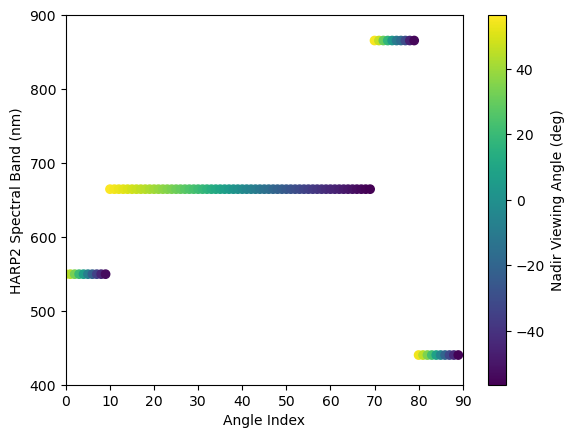

In [58]:
num_angles = H1C.sensors_views_bands.sensor_view_angle.size

#plot the distribution of angles, bands, and indices
fig,ax=plt.subplots()
cf=ax.scatter(np.linspace(0,num_angles-1,num_angles),H1C.sensors_views_bands.intensity_wavelength,c=H1C.sensors_views_bands.sensor_view_angle)
ax.set_xlabel("Angle Index")
ax.set_ylabel("HARP2 Spectral Band (nm)")
ax.set_ylim(400,900)
ax.set_xlim(0,90)
plt.colorbar(cf,label="Nadir Viewing Angle (deg)",ax=ax)

In [59]:
H1C.sensors_views_bands.intensity_wavelength.shape

(90, 1)

In [60]:
H1C.observation_data.i

<xarray.DataArray 'i' (bins_along_track: 395, bins_across_track: 519,
                       number_of_views: 90, intensity_bands_per_view: 1)> Size: 74MB
[18450450 values with dtype=float32]
Dimensions without coordinates: bins_along_track, bins_across_track,
                                number_of_views, intensity_bands_per_view
Attributes:
    long_name:  I Stokes vector component
    units:      W/m2/micron/sr
    valid_min:  0
    valid_max:  32760

In [61]:
print(np.nanmax(H1C.observation_data.i[:,:,60,0]))

430.7


In [62]:
H1C.observation_data.i.attrs

{'long_name': 'I Stokes vector component',
 'units': 'W/m2/micron/sr',
 'valid_min': 0,
 'valid_max': 32760}

In [54]:
8614*0.05

430.70000000000005

In [67]:
print(H1C.sensors_views_bands.sensor_view_angle[84])

<xarray.DataArray 'sensor_view_angle' ()> Size: 4B
array(8.53, dtype=float32)
Attributes:
    long_name:  Along-track view angles of sensor
    units:      degrees
    valid_min:  -80.0
    valid_max:  80.0


/tmp/ipykernel_1276/4034462612.py:8: RuntimeWarning: invalid value encountered in cast
  RGB_image=np.array(RGB,dtype=np.uint8)


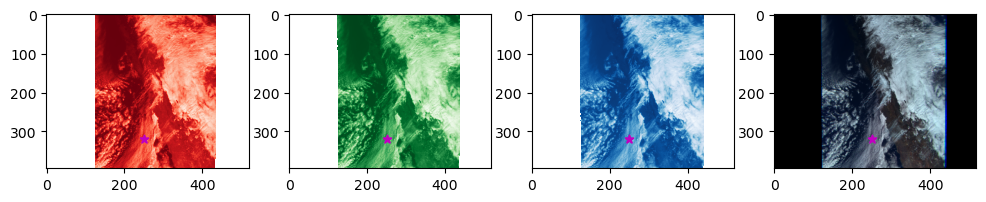

In [116]:
R = H1C.observation_data.i[:,:,40,0]
G = H1C.observation_data.i[:,:,4,0]
B = H1C.observation_data.i[:,:,84,0]
RGB_max=np.max([np.nanmax(R),np.nanmax(G),np.nanmax(B)])
RGB_min=np.min([np.nanmin(R),np.nanmin(G),np.nanmin(B)])
RGB_scale=(RGB_max-RGB_min)/255.0
RGB=np.stack([(R-RGB_min)/RGB_scale,(G-RGB_min)/RGB_scale,(B-RGB_min)/RGB_scale],axis=2)
RGB_image=np.array(RGB,dtype=np.uint8)
fig,ax=plt.subplots(1,4,figsize=[12,3])
ax[0].imshow(R,cmap='Reds_r')
ax[1].imshow(G,cmap='Greens_r')
ax[2].imshow(B,cmap='Blues_r')
ax[3].imshow(RGB_image)
x0_index=250
y0_index=320
ax[0].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[1].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[2].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[3].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')

0.00024999998 1.1797


/tmp/ipykernel_1276/2546412659.py:11: RuntimeWarning: invalid value encountered in cast
  RGB_image=np.array(RGB,dtype=np.uint8)


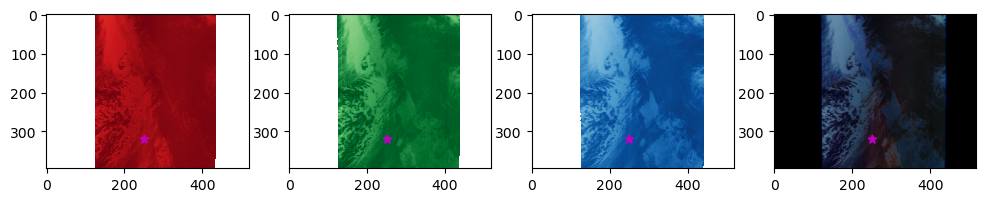

In [130]:
R = H1C.observation_data.dolp[:,:,40,0]
G = H1C.observation_data.dolp[:,:,4,0]
B = H1C.observation_data.dolp[:,:,84,0]
RGB_max=np.max([np.nanmax(R),np.nanmax(G),np.nanmax(B)])
RGB_min=np.min([np.nanmin(R),np.nanmin(G),np.nanmin(B)])
print(RGB_min,RGB_max)
RGB_scale=(RGB_max-RGB_min)/255.0
#RGB=np.stack([(R-RGB_min)/RGB_scale,(G-RGB_min)/RGB_scale,(B-RGB_min)/RGB_scale],axis=2)
RGB=np.stack([R/0.9*255,G/0.9*255,B/0.9*255],axis=2)

RGB_image=np.array(RGB,dtype=np.uint8)
fig,ax=plt.subplots(1,4,figsize=[12,3])
ax[0].imshow(R,cmap='Reds_r')
ax[1].imshow(G,cmap='Greens_r')
ax[2].imshow(B,cmap='Blues_r')
ax[3].imshow(RGB_image)
ax[0].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[1].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[2].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')
ax[3].scatter([x0_index,x0_index],[y0_index,y0_index],marker='*',facecolor='m')

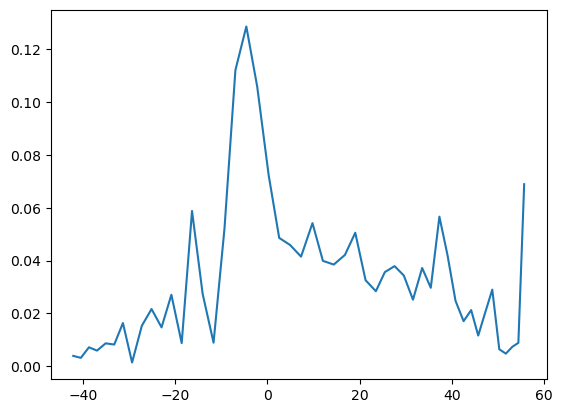

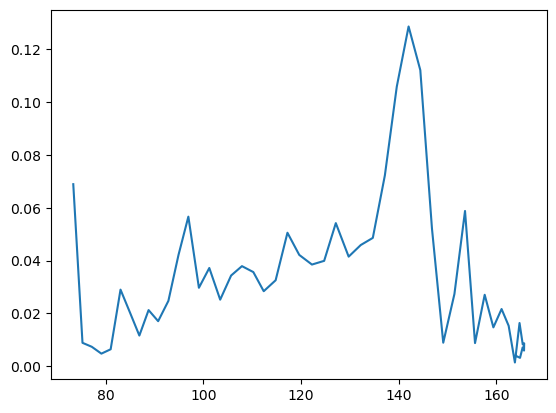

In [122]:
fig,ax=plt.subplots()
ax.plot(H1C.sensors_views_bands.sensor_view_angle[10:60],H1C.observation_data.dolp[y0_index,x0_index,10:60,0])

fig,ax=plt.subplots()
ax.plot(H1C.geolocation_data.scattering_angle[y0_index,x0_index,10:60],H1C.observation_data.dolp[y0_index,x0_index,10:60,0])


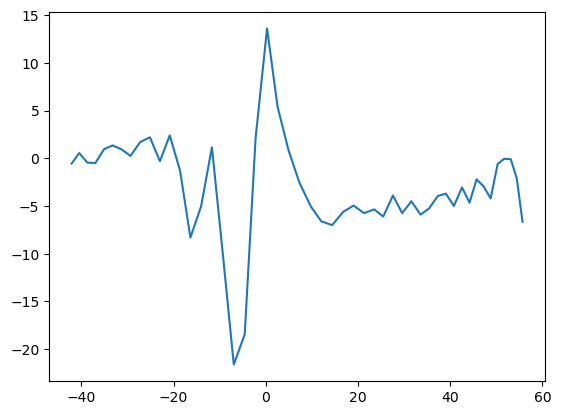

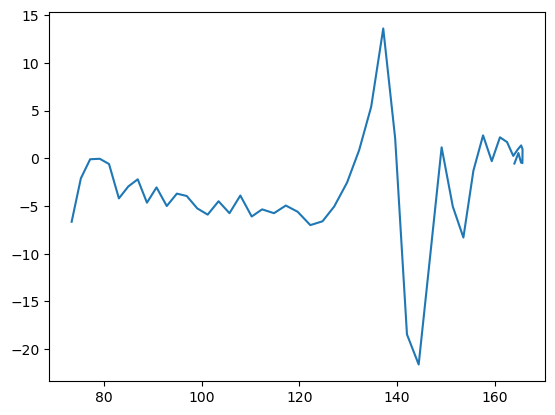

In [132]:
fig,ax=plt.subplots()
ax.plot(H1C.sensors_views_bands.sensor_view_angle[10:60],H1C.observation_data.q[y0_index,x0_index,10:60,0])
ax.plot(H1C.sensors_views_bands.sensor_view_angle[10:60],H1C.observation_data.u[y0_index,x0_index,10:60,0],ls='dashed')

fig,ax=plt.subplots()
ax.plot(H1C.geolocation_data.scattering_angle[y0_index,x0_index,10:60],H1C.observation_data.q[y0_index,x0_index,10:60,0])
ax.plot(H1C.geolocation_data.scattering_angle[y0_index,x0_index,10:60],H1C.observation_data.u[y0_index,x0_index,10:60,0])
